# 1B. FNN - Fashion MNIST
FNN baseline.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tensorflow import keras
from tensorflow.keras import layers

In [2]:
train = pd.read_csv("../datasets/FNN and CNN/Fashion MNIST/fashion-mnist_train.csv")
test = pd.read_csv("../datasets/FNN and CNN/Fashion MNIST/fashion-mnist_test.csv")

y_train = train["label"].to_numpy()
y_test = test["label"].to_numpy()
x_train = train.drop(columns="label").to_numpy()
x_test = test.drop(columns="label").to_numpy()

print(x_train.shape, x_test.shape)

(60000, 784) (10000, 784)


In [3]:
model = keras.Sequential([
    layers.Input(shape=(784,)),
    layers.Rescaling(1./255),
    layers.Dense(128, activation="relu"),
    layers.Dense(10, activation="softmax"),
])
model.compile(optimizer="adam", loss="sparse_categorical_crossentropy", metrics=["accuracy"])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 101,770 (397.54 KB)

 Trainable params: 101,770 (397.54 KB)

 Non-trainable params: 0 (0.00 B)

In [4]:
history = model.fit(x_train, y_train, validation_data=(x_test, y_test), epochs=5)

Epoch 1/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 877us/step - accuracy: 0.8254 - loss: 0.5006 - val_accuracy: 0.8568 - val_loss: 0.3950
Epoch 2/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 821us/step - accuracy: 0.8633 - loss: 0.3779 - val_accuracy: 0.8708 - val_loss: 0.3589
Epoch 3/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 831us/step - accuracy: 0.8754 - loss: 0.3392 - val_accuracy: 0.8727 - val_loss: 0.3492
Epoch 4/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 846us/step - accuracy: 0.8843 - loss: 0.3153 - val_accuracy: 0.8801 - val_loss: 0.3287
Epoch 5/5
1875/1875 ━━━━━━━━━━━━━━━━━━━━ 2s 820us/step - accuracy: 0.8894 - loss: 0.2980 - val_accuracy: 0.8779 - val_loss: 0.3323


In [5]:
loss, acc = model.evaluate(x_test, y_test)
print(f"test loss: {loss:.4f}  test accuracy: {acc:.4f}")

  1/313 ━━━━━━━━━━━━━━━━━━━━ 2s 7ms/step - accuracy: 0.8750 - loss: 0.3918

117/313 ━━━━━━━━━━━━━━━━━━━━ 0s 432us/step - accuracy: 0.8745 - loss: 0.3384

236/313 ━━━━━━━━━━━━━━━━━━━━ 0s 426us/step - accuracy: 0.8750 - loss: 0.3400

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 445us/step - accuracy: 0.8779 - loss: 0.3323


test loss: 0.3323  test accuracy: 0.8779


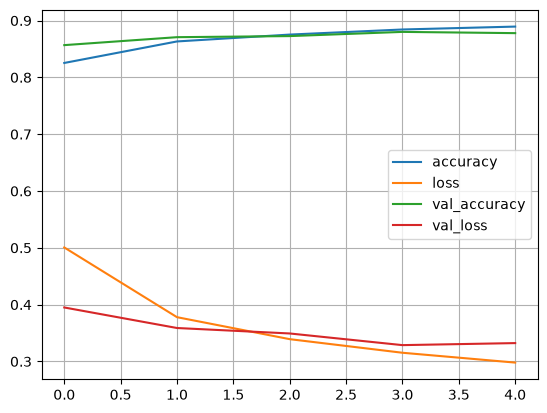

In [6]:
for k, v in history.history.items():
    plt.plot(v, label=k)
plt.legend()
plt.grid()
plt.show()